In [10]:
from pathlib import Path
import sys
import pandas as pd

project_root = Path.cwd()
if not (project_root / "models").is_dir():
    project_root = project_root.parent

# Put this project first and clear any unrelated installed package named `models`.
sys.path.insert(0, str(project_root))
for module_name in tuple(sys.modules):
    if module_name == "models" or module_name.startswith("models."):
        del sys.modules[module_name]

from models.windows import WindowBuilder, WindowedForecaster

# Load the prepared monthly training data from the project root.
data_path = project_root / "data" / "processed" / "training_data.pkl"
panel = pd.read_pickle(data_path).dropna(subset=["gross_qty"])
print(f"Loaded {len(panel):,} rows from {data_path}")

Loaded 20,309 rows from d:\demond_forcasting\data\processed\training_data.pkl


In [16]:
def train_nhits(data, levels, n_seeds=3):
    return [train_one(data, levels, seed) for seed in range(n_seeds)]

def predict_nhits(models, data):
    X, M, C = make_tensors(data)
    with torch.no_grad():
        return np.mean([m(X, M, C).numpy() for m in models], axis=0)

In [17]:
def make_tensors(data):
    X = torch.tensor(data["X"], dtype=torch.float32)
    M = torch.tensor(data["M"], dtype=torch.float32)
    C = torch.tensor(data["C"], dtype=torch.float32)
    return X, M, C

In [18]:
def pinball(pred, y, tau):
    d = y.unsqueeze(1) - pred
    return torch.maximum(tau * d, (tau - 1) * d).mean()

In [19]:
class Block(nn.Module):
    def __init__(self, L, n_cov, n_levels, pool, hidden=64):
        super().__init__()
        assert L % pool == 0, "window length must be divisible by the pool size"
        self.pool = pool
        self.mlp = nn.Sequential(nn.Linear(2 * (L // pool) + n_cov, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU())
        self.back = nn.Linear(hidden, L)
        self.fore = nn.Linear(hidden, n_levels)

    def forward(self, x, m, c):
        px = F.avg_pool1d(x.unsqueeze(1), self.pool).squeeze(1)
        pm = F.avg_pool1d(m.unsqueeze(1), self.pool).squeeze(1)
        h = self.mlp(torch.cat([px, pm, c], dim=1))
        return self.back(h), self.fore(h)

In [20]:
class NHiTS(nn.Module):
    def __init__(self, L, n_cov, n_levels, pools=(3, 1), hidden=64):
        super().__init__()
        self.blocks = nn.ModuleList([Block(L, n_cov, n_levels, p, hidden) for p in pools])

    def forward(self, x, m, c):
        forecast = 0
        for block in self.blocks:
            back, f = block(x, m, c)
            x = (x - back) * m
            forecast = forecast + f
        return forecast

In [21]:
# a zero-parameter baseline that exercises the whole pipeline: quantiles of the real months inside each window (log scale)
from tkinter import BEVEL

import numpy as np
def _train_baseline(data, levels):
    return None

def _predict_baseline(model, data):
    return np.array([np.quantile(x[m > 0], LEVELS) for x, m in zip(data["X"], data["M"])])



In [22]:
import torch
import torch.nn.functional as F
from torch import nn

def make_tensors(data):
    X = torch.tensor(data["X"], dtype=torch.float32)
    M = torch.tensor(data["M"], dtype=torch.float32)
    C = torch.tensor(data["C"], dtype=torch.float32)
    return X, M, C

In [23]:
def train_one(data, levels, seed, epochs=200, lr=1e-3, patience=20, batch=256, pools=(3, 1), hidden=64):
    torch.manual_seed(seed)
    X, M, C = make_tensors(data)
    y = torch.tensor(data["y"], dtype=torch.float32)
    tau = torch.tensor(levels, dtype=torch.float32)
    is_train = torch.tensor(data["t"] <= data["t"].max() - 3)
    tr_idx, va_idx = torch.where(is_train)[0], torch.where(~is_train)[0]
    model = NHiTS(X.shape[1], C.shape[1], len(levels), pools, hidden)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    best, best_state, wait = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        order = tr_idx[torch.randperm(len(tr_idx))]
        for i in range(0, len(order), batch):
            b = order[i:i + batch]
            opt.zero_grad()
            loss = pinball(model(X[b], M[b], C[b]), y[b], tau)
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = pinball(model(X[va_idx], M[va_idx], C[va_idx]), y[va_idx], tau).item()
        if val < best - 1e-4:
            best, wait, best_state = val, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model.eval()

In [24]:
import numpy as np

from models.backtest import assert_no_leakage

LEVELS = [0.1, 0.5, 0.8, 0.9, 0.95]

cutoff_dev = int(panel["time_idx"].max()) - 6
train_w = panel[panel["time_idx"] <= cutoff_dev]      # months up to 35
val_dev = panel[panel["time_idx"] > cutoff_dev]       # months 36-41
print(panel.shape, "| train rows:", len(train_w), "| validation rows:", len(val_dev))

(20309, 18) | train rows: 17068 | validation rows: 3241


In [25]:
needed = ["Site", "Brand", "Range", "time_idx", "gross_qty", "month_sin", "month_cos", "range_age_months"]
assert all(c in panel.columns for c in needed), [c for c in needed if c not in panel.columns]

builder = WindowBuilder(window=6)
d_train = builder.arrays(train_w, train_w)             # one window per training row
keep = d_train["ok"]                                    # drop rows with no earlier month (age 0)
data_train = {k: v[keep] for k, v in d_train.items() if k != "ok"}

print("shapes:", {k: v.shape for k, v in data_train.items()})
print("rows kept:", int(keep.sum()), "of", len(keep), "| NaN anywhere:", any(bool(np.isnan(v).any()) for v in data_train.values()))
print("padded windows: %.1f%%" % (100 * (data_train["M"].sum(axis=1) < 6).mean()),
      "| y range:", round(data_train["y"].min(), 2), "to", round(data_train["y"].max(), 2),
      "| months", data_train["t"].min(), "to", data_train["t"].max())

shapes: {'X': (16538, 6), 'M': (16538, 6), 'C': (16538, 5), 'y': (16538,), 't': (16538,)}
rows kept: 16538 of 17068 | NaN anywhere: False
padded windows: 16.0% | y range: 0.0 to 11.97 | months 1 to 35


In [26]:
Xt, Mt, Ct = make_tensors(data_train)
yt = torch.tensor(data_train["y"], dtype=torch.float32)
tau = torch.tensor(LEVELS, dtype=torch.float32)

net = NHiTS(Xt.shape[1], Ct.shape[1], len(LEVELS))
with torch.no_grad():
    out = net(Xt[:256], Mt[:256], Ct[:256])
print("output shape:", tuple(out.shape), "| untrained loss:", round(pinball(out, yt[:256], tau).item(), 3),
      "| params:", sum(p.numel() for p in net.parameters()))

output shape: (256, 5) | untrained loss: 3.864 | params: 11542


In [27]:
_net = NHiTS(6, 5, len(LEVELS))
_opt = torch.optim.Adam(_net.parameters(), lr=1e-2)
for _step in range(400):
    _opt.zero_grad()
    _loss = pinball(_net(Xt[:64], Mt[:64], Ct[:64]), yt[:64], tau)
    _loss.backward()
    _opt.step()
    if _step in (0, 399):
        print("step", _step, "loss", round(_loss.item(), 3))

step 0 loss 4.476
step 399 loss 0.051


In [30]:
from models.evaluation import Evaluator
from models.quantile import NaiveLag1

wf_nhits = WindowedForecaster(LEVELS, lambda d, lv: train_nhits(d, lv, n_seeds=1), predict_nhits, WindowBuilder(window=6), name="nhits")
qf_nhits = wf_nhits.fit(train_w).predict(val_dev, panel)
# assert_no_leakage(wf_nhits, panel, val_dev)

evaluator = Evaluator(val_dev, val_dev["gross_qty"].to_numpy())
table_nhits = evaluator.table({"naive lag_1": NaiveLag1().predict(val_dev), "N-HiTS": qf_nhits})
table_nhits.round(3)

,MAE,WAPE,Bias,WAPE mature (age>=12),WAPE young (age<12),"coverage [P10,P90]",mean pinball,interval score,n_rows
naive lag_1,480.736,0.269,124.563,0.268,0.277,NaN,NaN,NaN,3185
N-HiTS,365.802,0.204,-89.043,0.204,0.267,0.896,136.927,2278.788,3185


In [29]:
_span = panel.groupby(["Site", "Brand", "Range"])["time_idx"].agg(["min", "max", "count"])
_span["missing_months"] = (_span["max"] - _span["min"] + 1) - _span["count"]
print("series:", len(_span), "| series with a missing month:", int((_span["missing_months"] > 0).sum()),
      "| total missing series-months:", int(_span["missing_months"].sum()))
print("duplicate series-month rows:", int(panel.duplicated(["Site", "Brand", "Range", "time_idx"]).sum()))
print("rows per month, last 6:", panel.groupby("time_idx").size().tail(6).to_dict())
_span[_span["missing_months"] > 0].head()

series: 586 | series with a missing month: 0 | total missing series-months: 0
duplicate series-month rows: 0
rows per month, last 6: {36: 530, 37: 530, 38: 530, 39: 530, 40: 535, 41: 586}


,,,min,max,count,missing_months
Site,Brand,Range,,,,


In [31]:
from models.plots import ForecastPlots
from models.evaluation import age_bucket

fp_nhits = ForecastPlots(val_dev, qf_nhits, name="N-HiTS")                                  # draws interpolated through all 5 levels
fp_nhits_curve = ForecastPlots(val_dev, qf_nhits, name="N-HiTS two-piece", sampler="two_piece")

print("rows scored:", len(fp_nhits.y), "of", len(val_dev))
print("scores (interp):   ", fp_nhits.scores())
print("scores (two-piece):", fp_nhits_curve.scores())
fp_nhits.shape_check().round(1)

rows scored: 3185 of 3241
scores (interp):    {'mean CRPS': 303.79195959756987, 'PIT max deviation': 0.12762951334379904}
scores (two-piece): {'mean CRPS': 300.60182421120106, 'PIT max deviation': 0.12731554160125588}


rows scored: 3185 of 3241
scores (interp):    {'mean CRPS': 303.79195959756987, 'PIT max deviation': 0.12762951334379904}
scores (two-piece): {'mean CRPS': 300.60182421120106, 'PIT max deviation': 0.12731554160125588}


,model total,curve total,gap %,median |row gap|
P80,6122459.1,6313960.0,3.1,0.4
P95,7308693.0,7595531.3,3.9,1.1


In [32]:
age_labels = age_bucket(val_dev["range_age_months"].to_numpy())
reliability_nhits = evaluator.reliability(qf_nhits).round(3)
by_age_nhits = evaluator.by_segment(qf_nhits, age_labels).round(3)
reliability_nhits, by_age_nhits

(         observed_below_strict  observed_below_inclusive
 nominal                                                 
 0.10                     0.023                     0.535
 0.50                     0.339                     0.729
 0.80                     0.858                     0.868
 0.90                     0.919                     0.919
 0.95                     0.941                     0.941,
                    n_rows      MAE   WAPE  coverage [P10,P90]
 0-2 (new)             7.0   12.779  0.688               1.000
 12+ (established)  3024.0  380.445  0.204               0.896
 3-11                154.0   94.308  0.266               0.896)

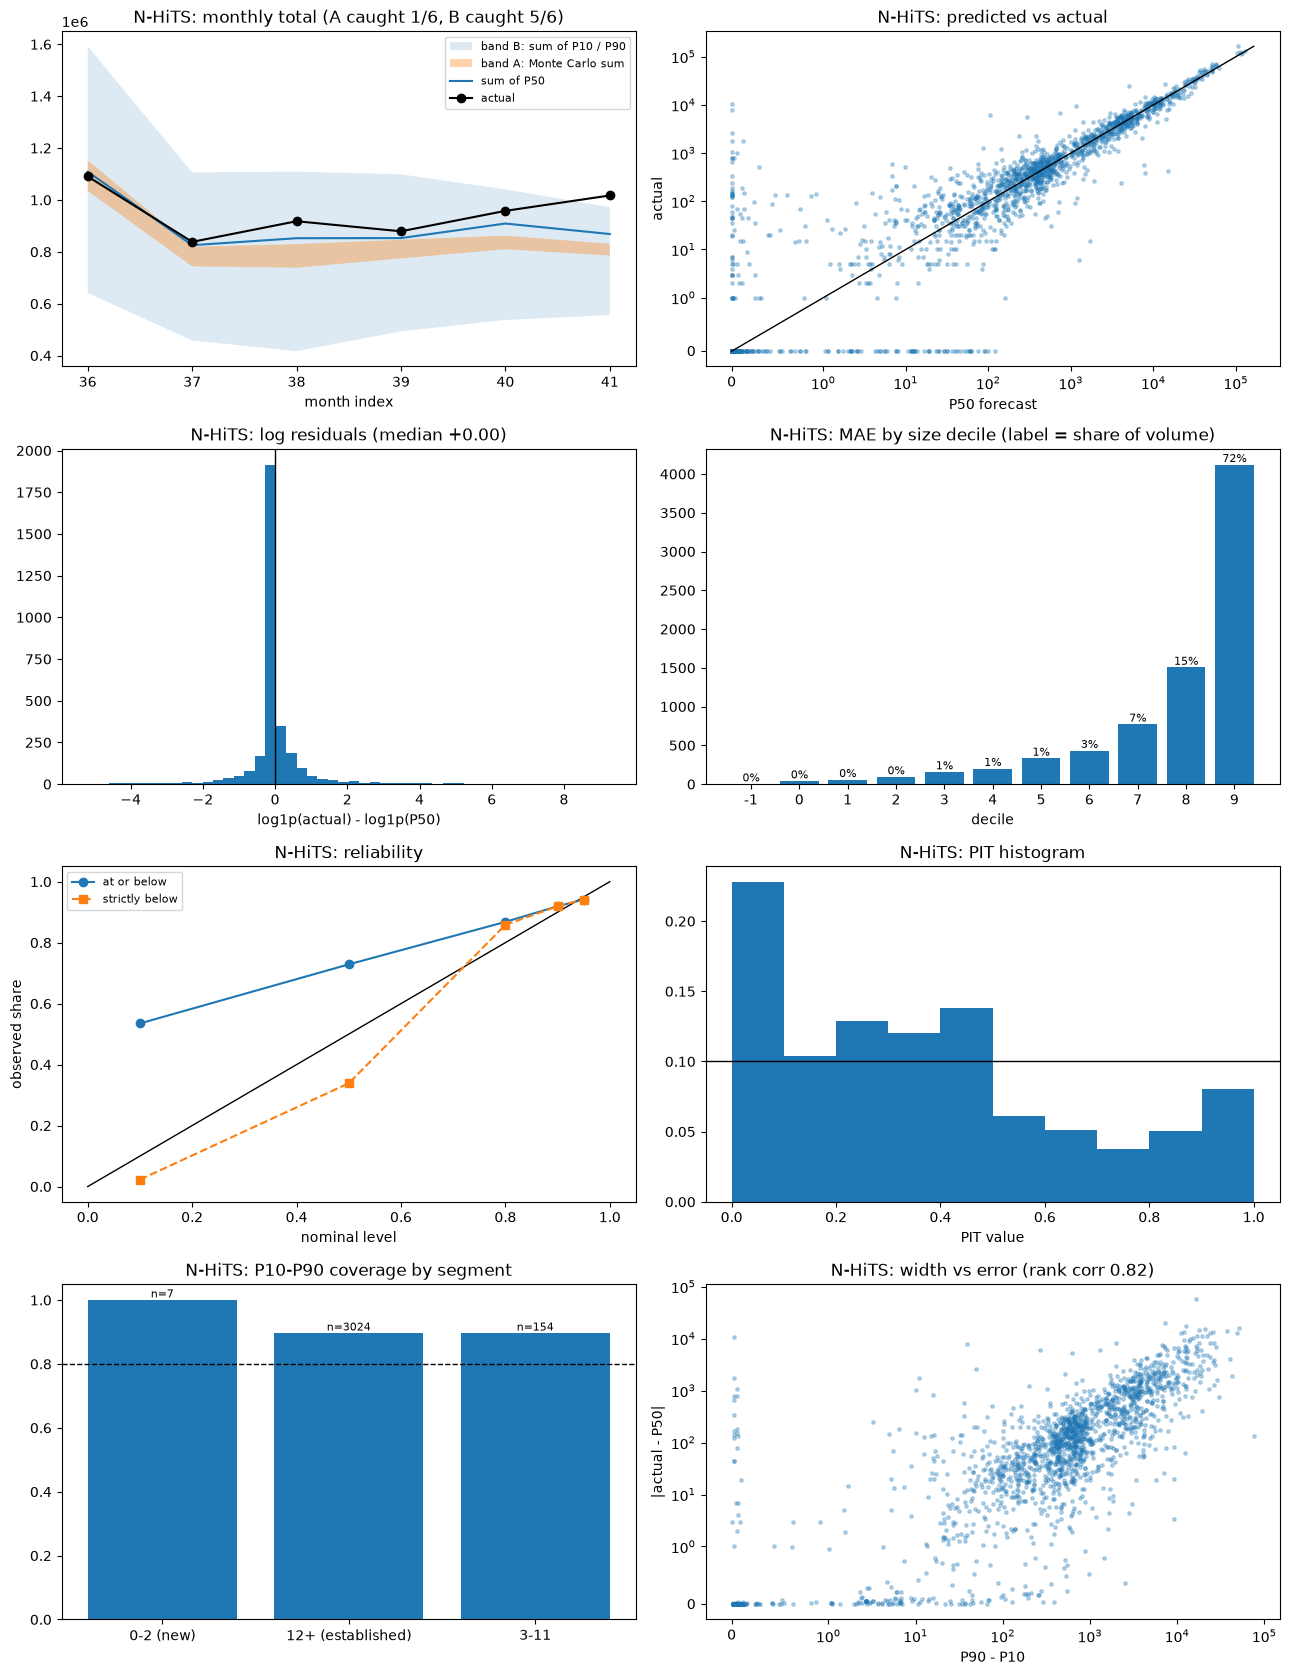

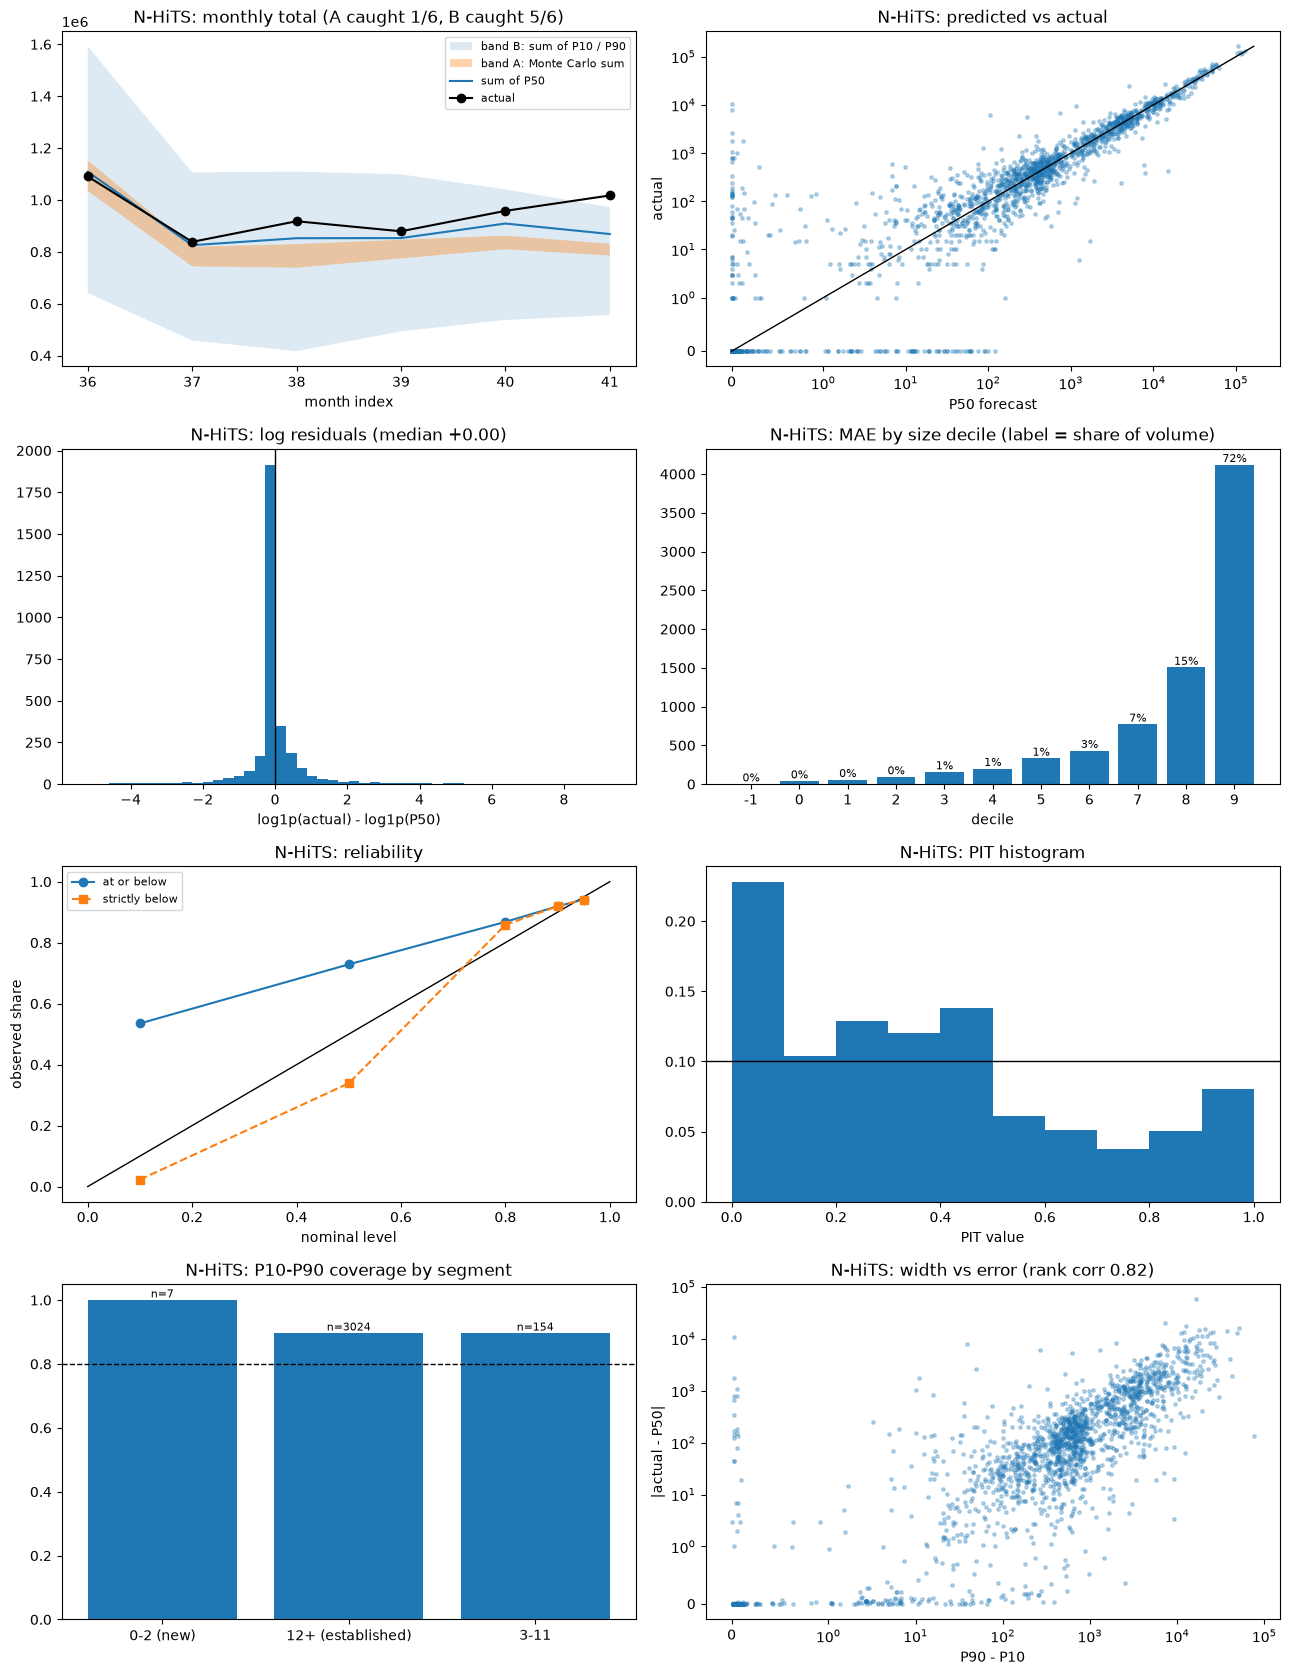

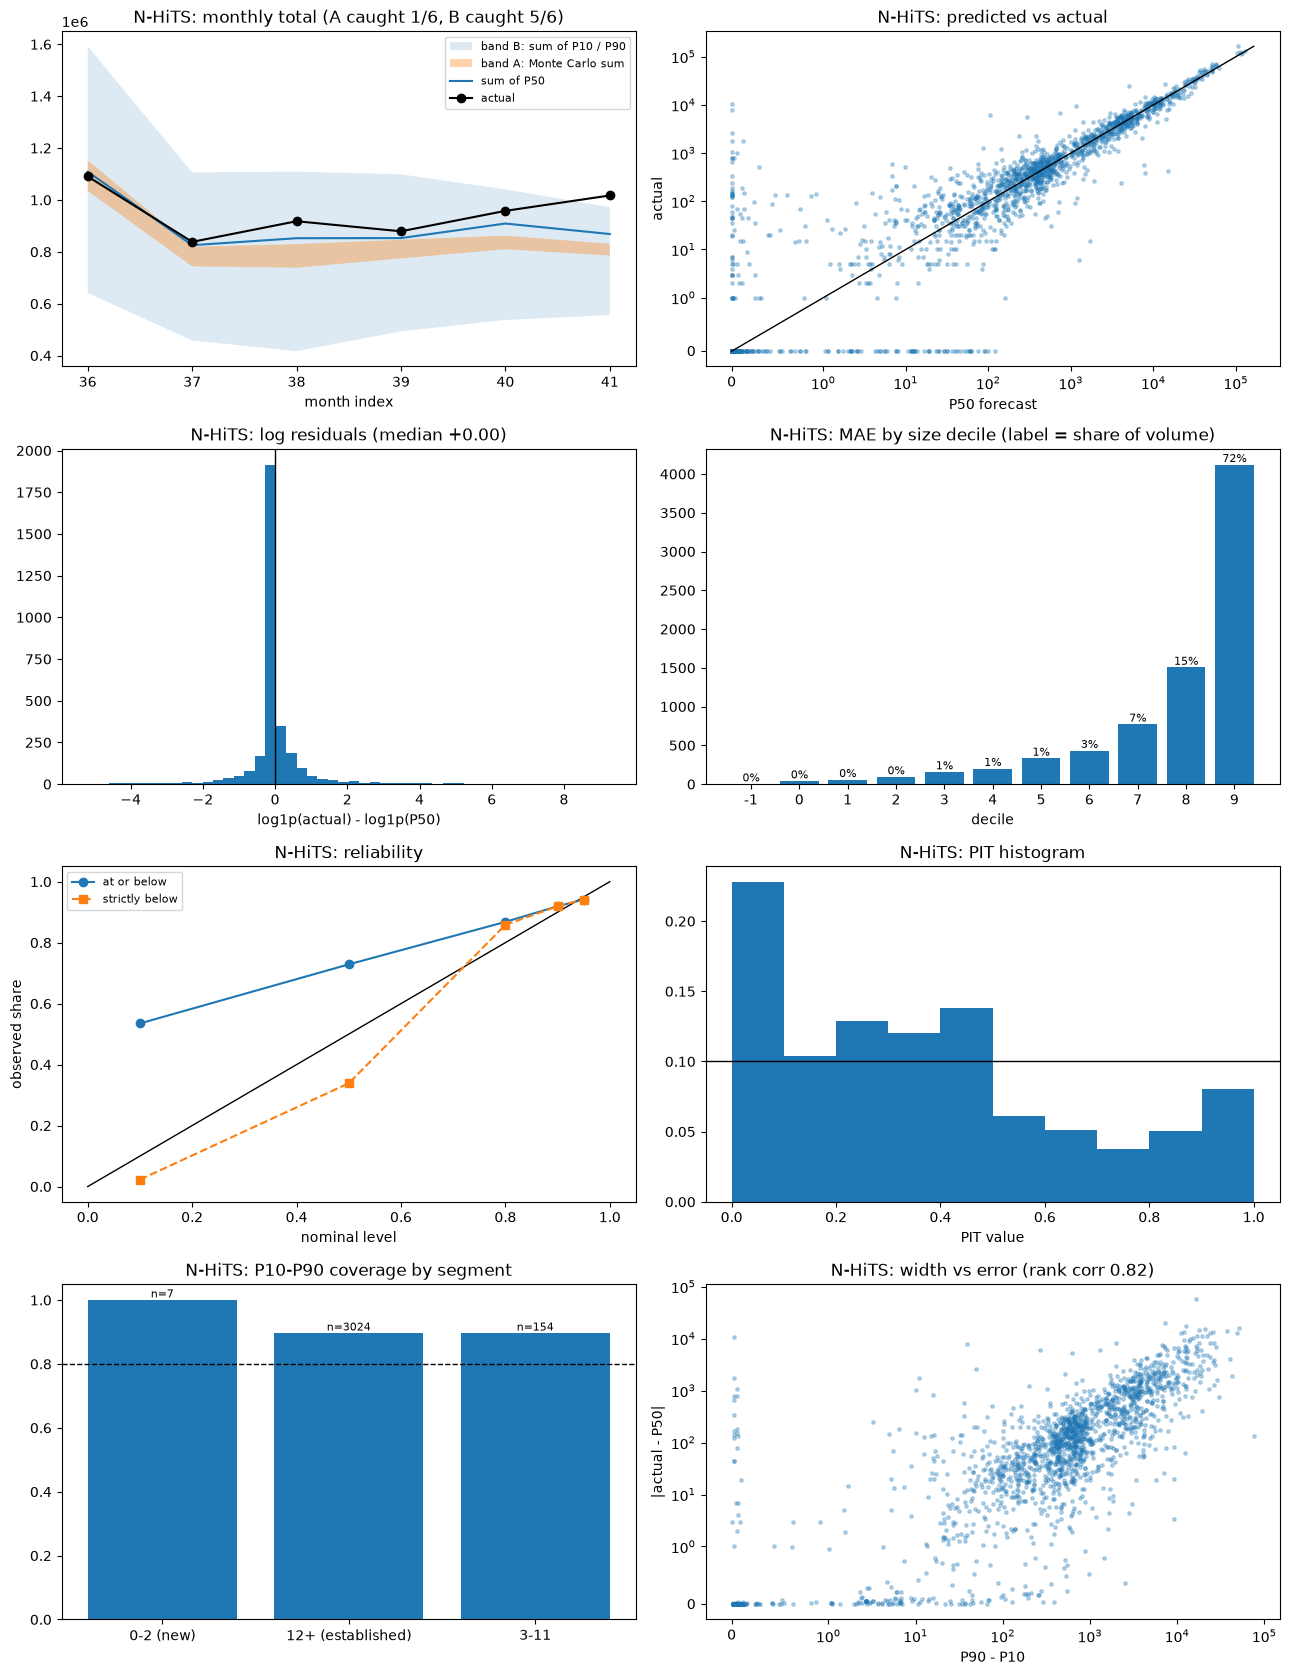

In [33]:
fig_nhits = fp_nhits.grid(labels=age_labels)
fig_nhits

In [34]:
from models.range_view import RangeView

view = RangeView(val_dev, qf_nhits, history=panel)       # adds each Range's series up and draws Monte Carlo totals
summary_ranges = view.summary()                           # one line per Range, smallest to largest
print(len(view.order), "Ranges | smallest:", view.order[:3], "| largest:", view.order[-3:])
summary_ranges.round(2)

10 Ranges | smallest: ['SC160070', 'SC160065', 'SC160023'] | largest: ['SC160005', 'SC160028', 'SC160040']


,volume,P50 total,bias %,WAPE,coverage A,coverage B,series,months
Range,,,,,,,,
SC160070,1742.0,2799.55,60.71,0.82,1.00,1.00,3,6
SC160065,29335.0,28852.80,-1.64,0.27,0.50,0.83,21,6
SC160023,45037.0,34446.74,-23.51,0.50,0.50,0.83,24,6
SC160009,49721.0,74049.93,48.93,0.49,0.17,1.00,26,6
SC169999,63433.0,6550.72,-89.67,0.90,0.00,0.67,84,6
SC160050,265159.0,246836.22,-6.91,0.07,0.83,1.00,26,6
SC160049,329971.0,377239.37,14.33,0.17,0.83,1.00,108,6
SC160005,906542.0,855439.48,-5.64,0.10,0.67,1.00,112,6
SC160028,1150883.0,1070097.74,-7.02,0.09,0.67,0.83,52,6


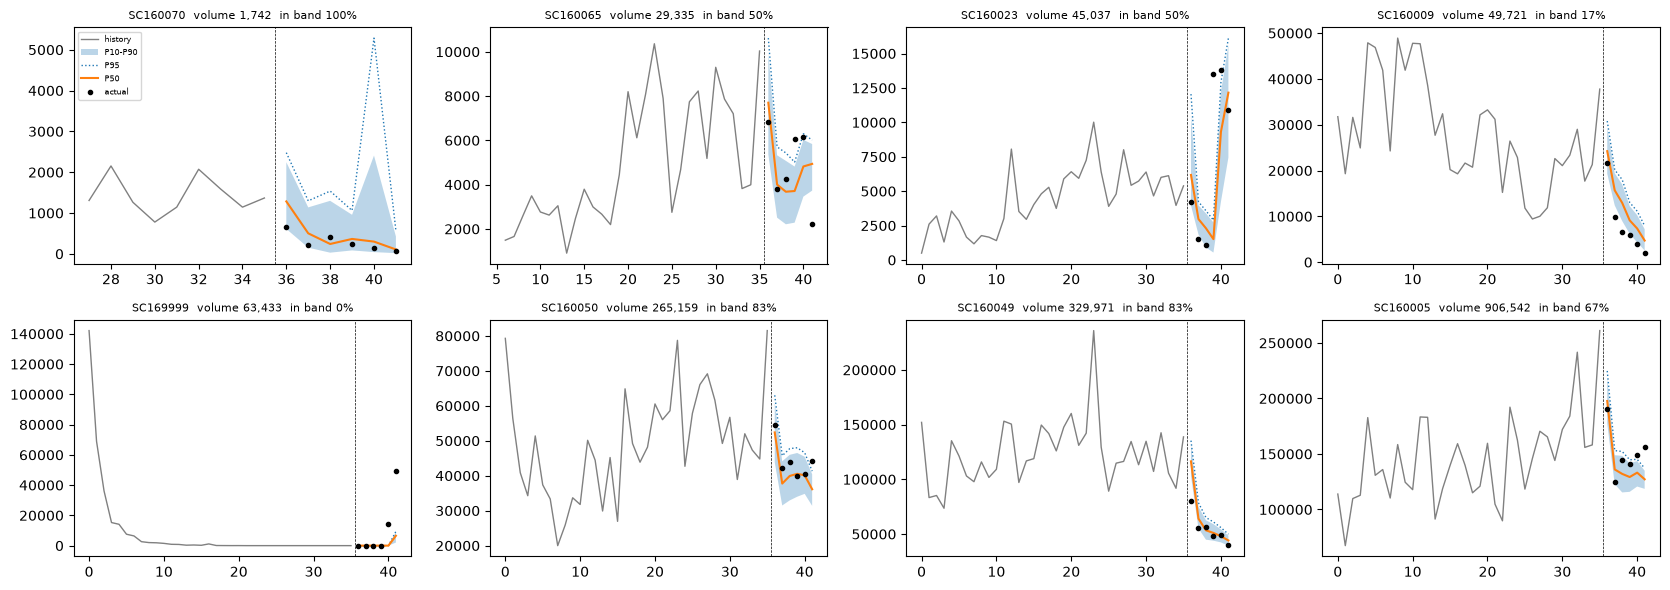

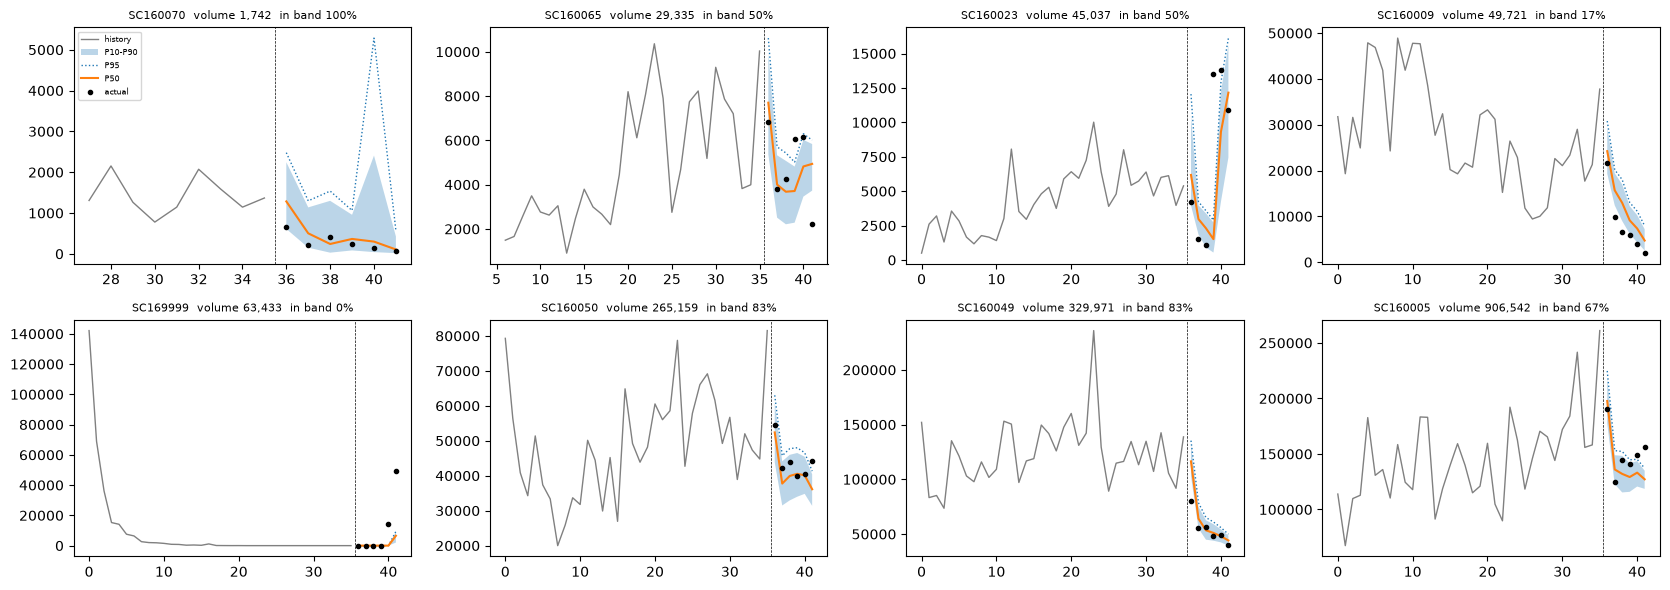

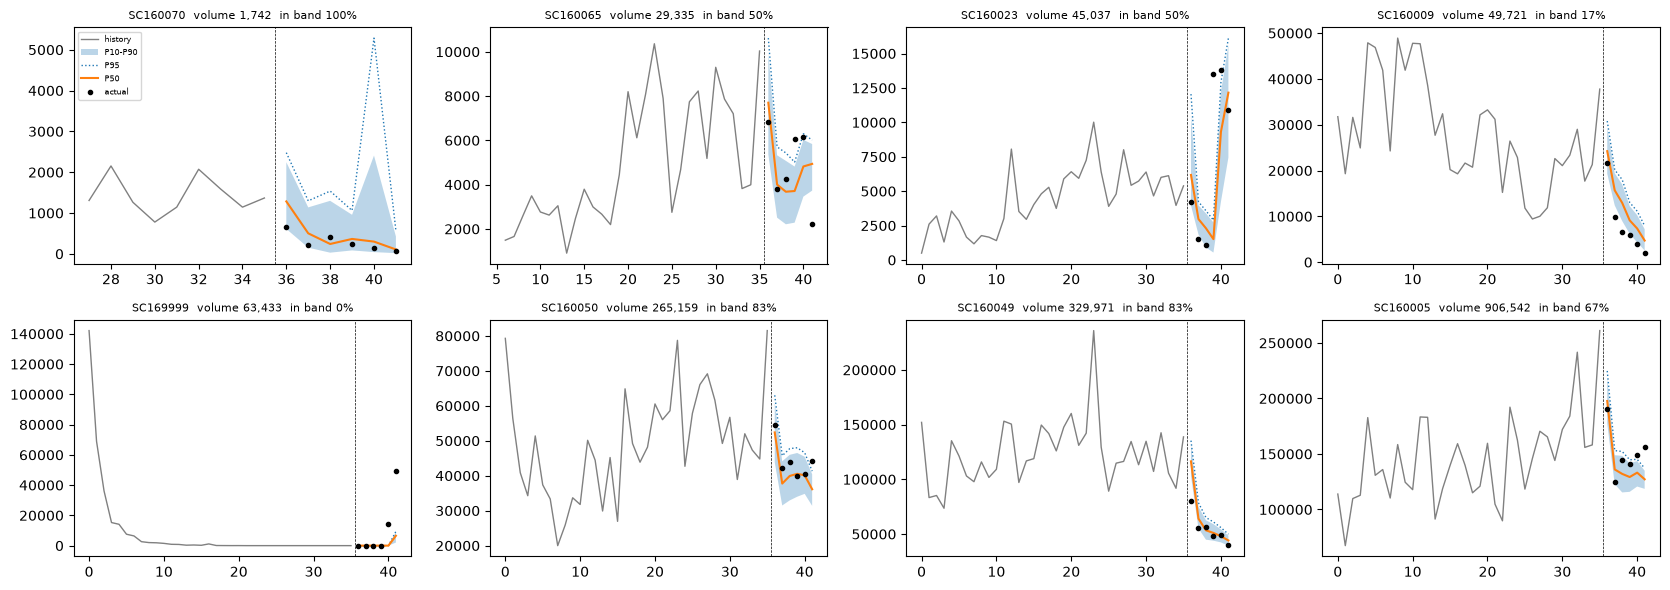

In [35]:
view.plot(view.order[:8], scale="raw")

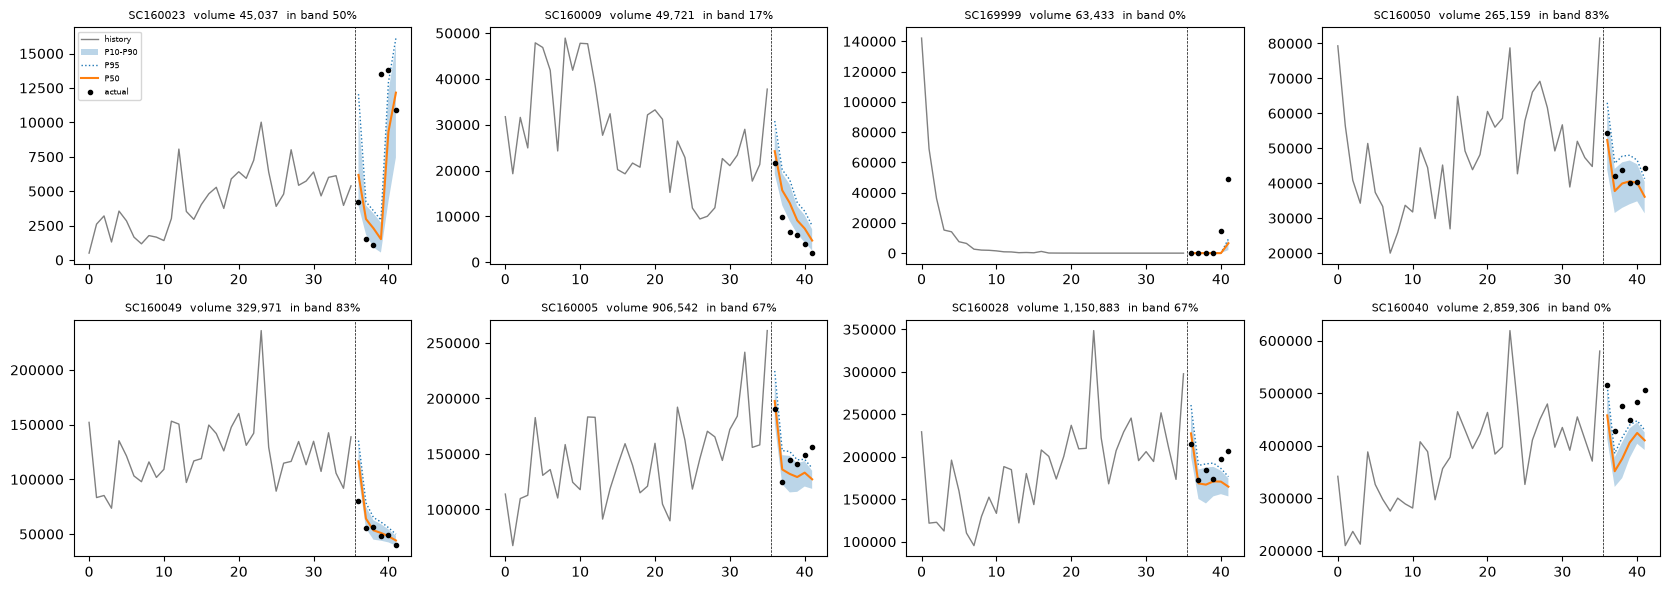

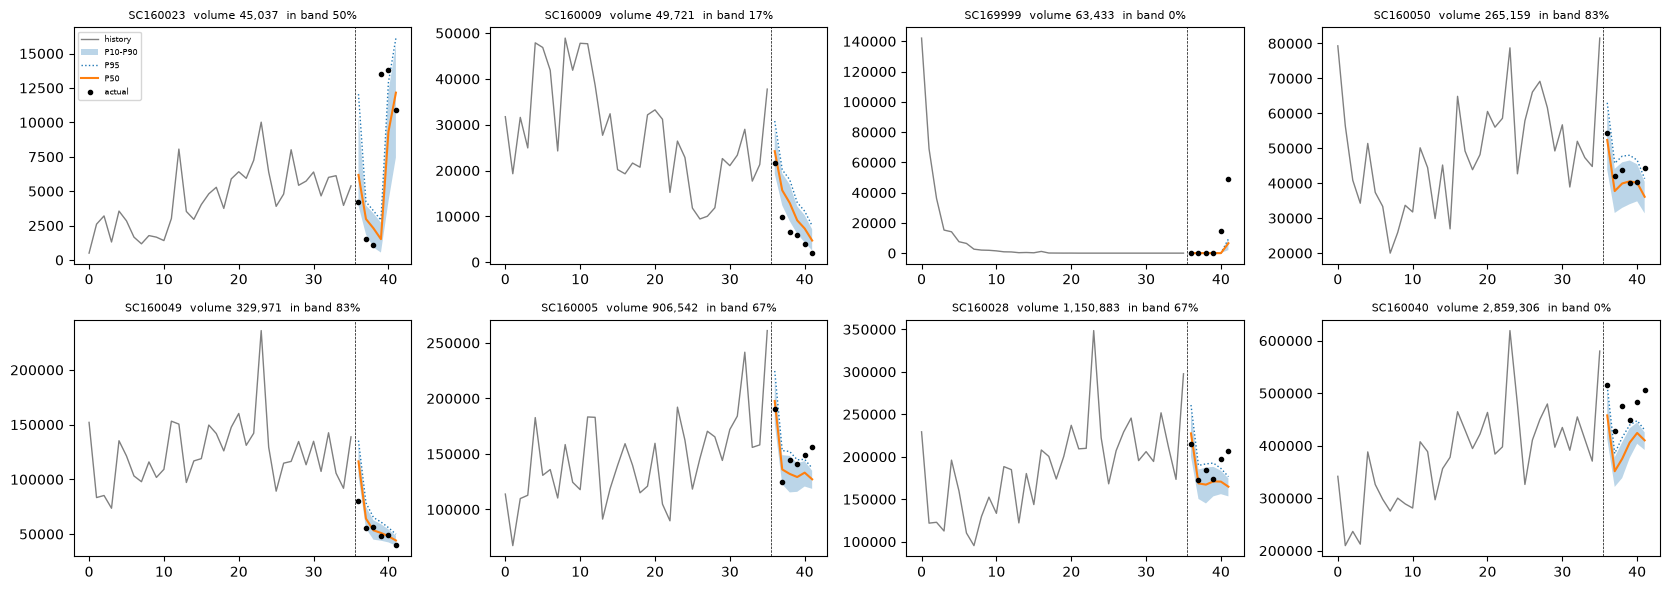

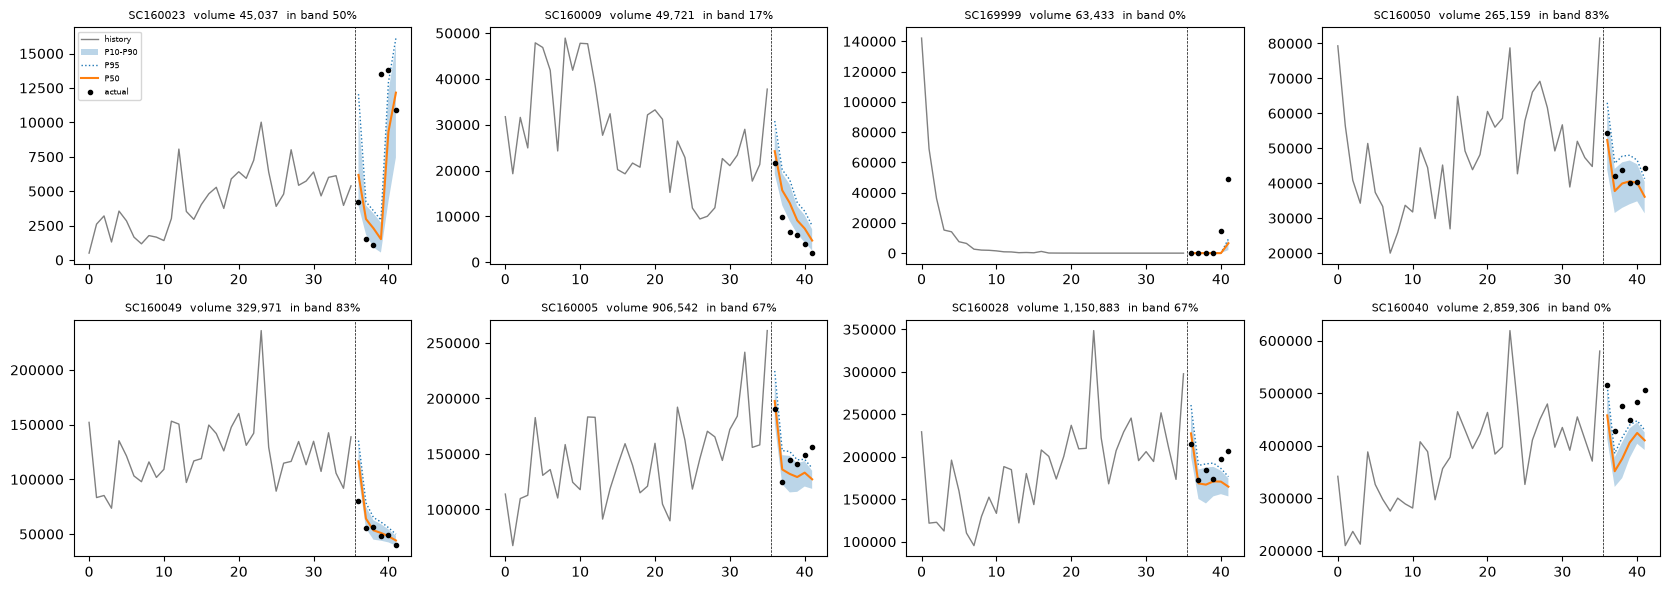

In [36]:
view.plot(view.order[-8:], scale="raw")

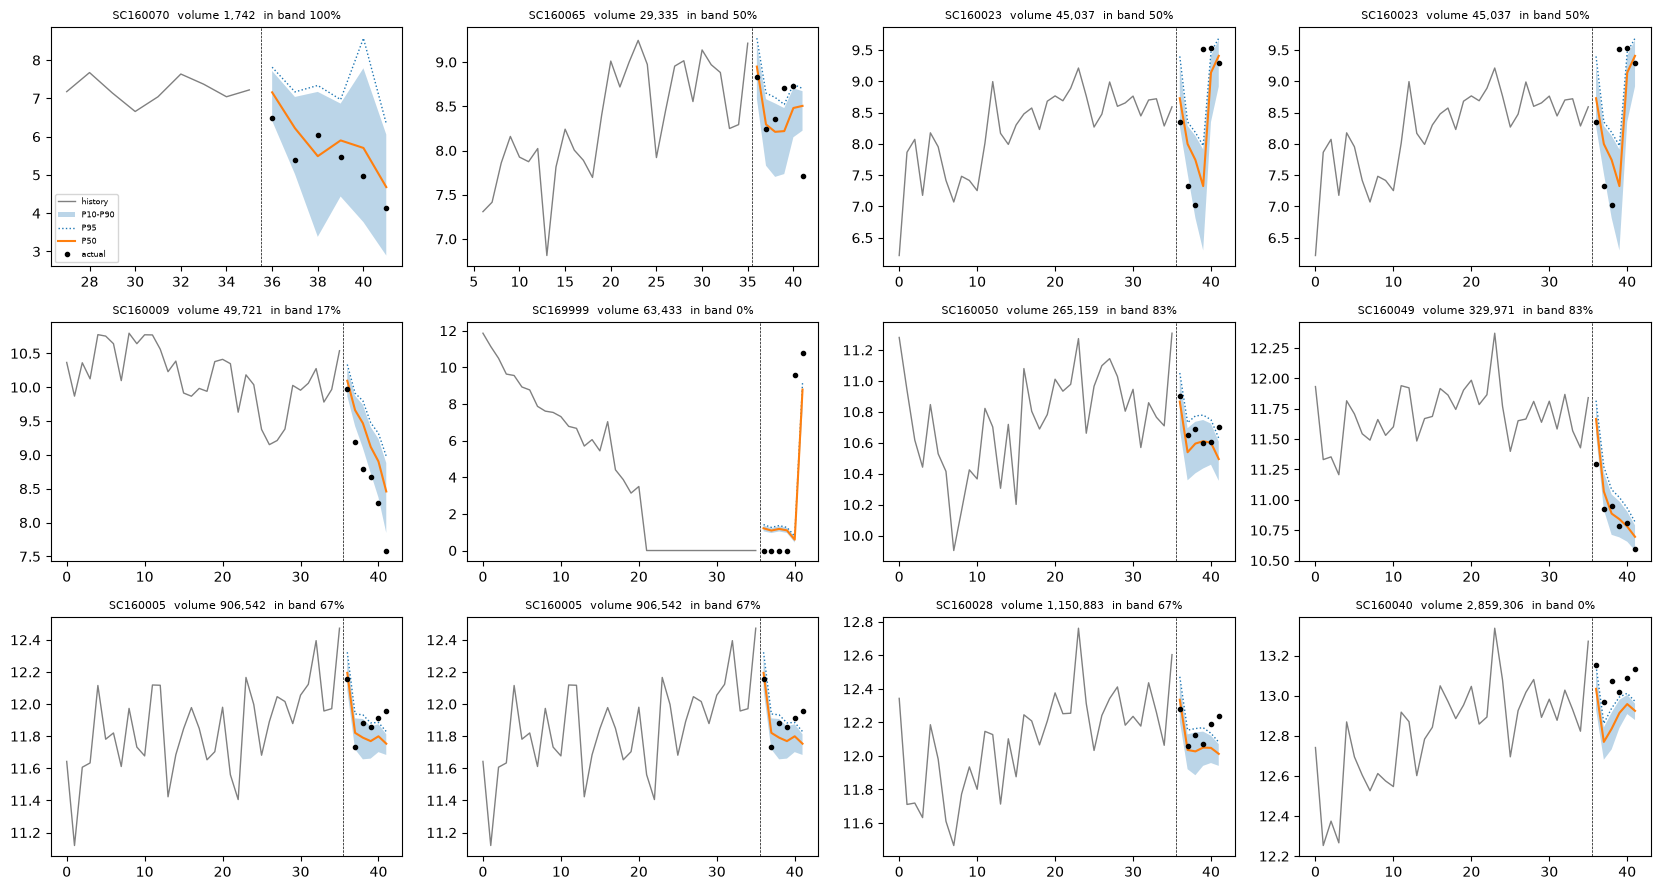

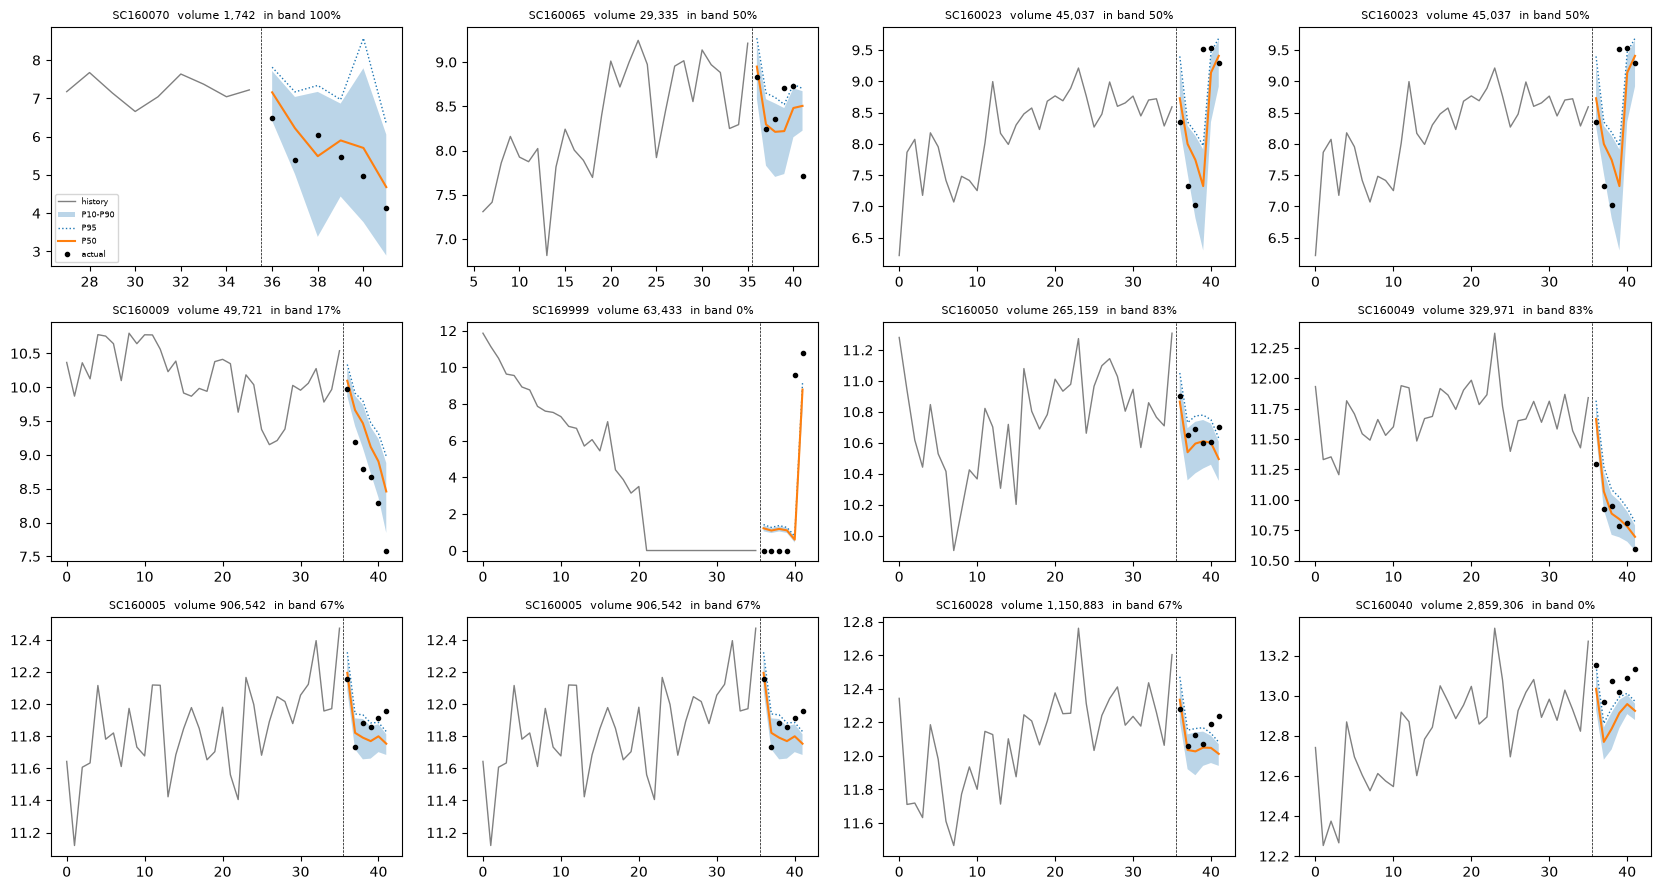

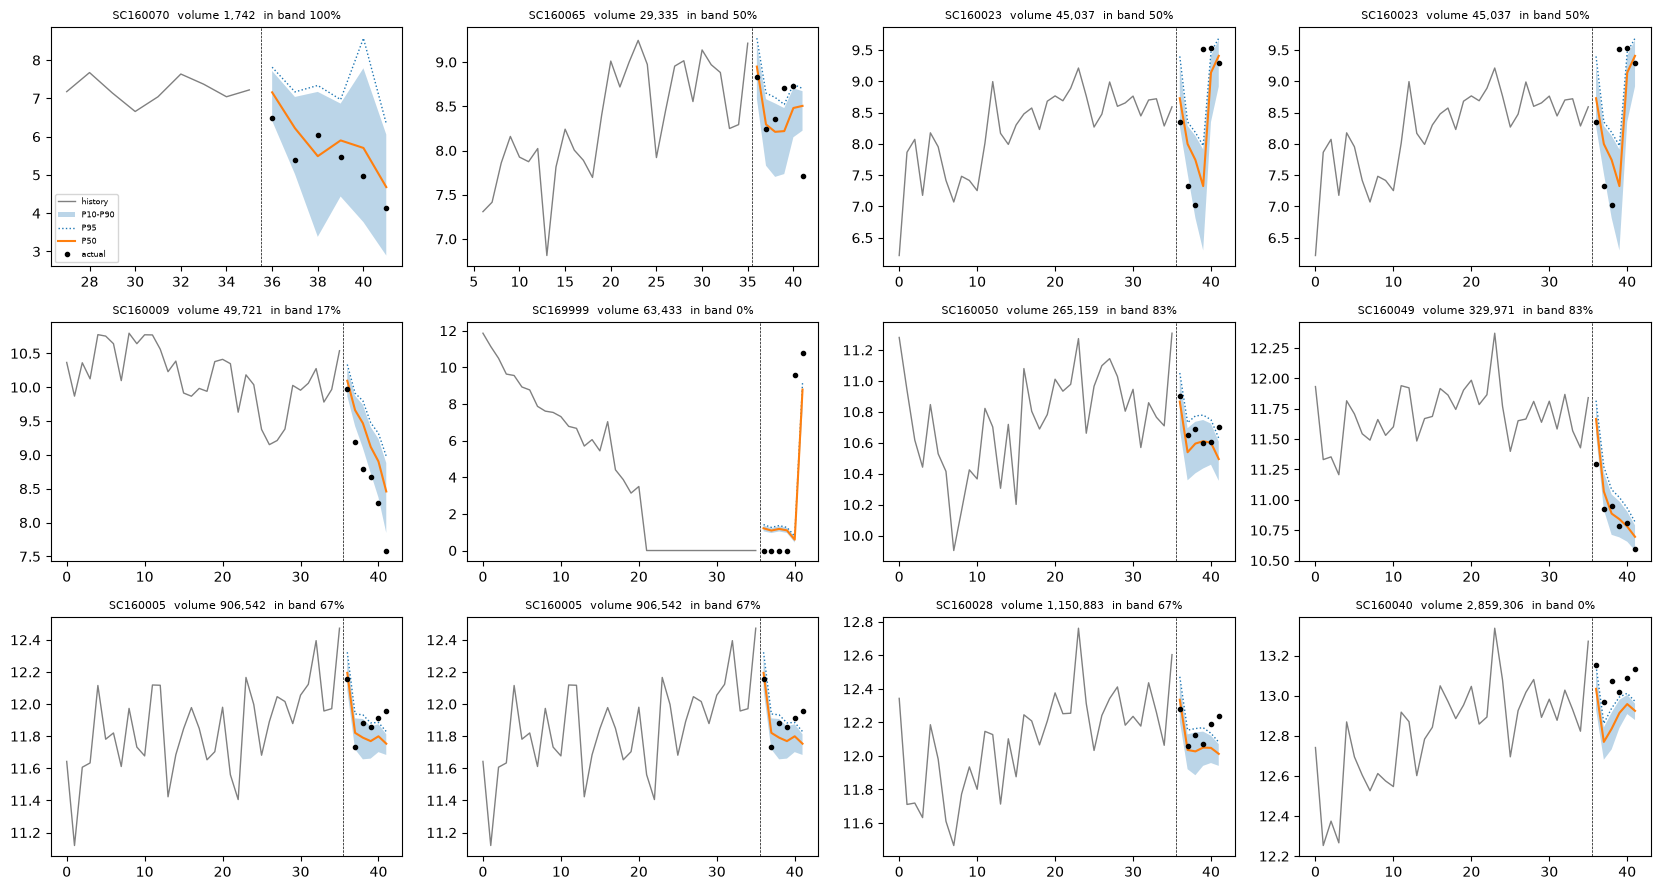

In [37]:
view.plot(view.pick(12), scale="log1p")

In [38]:
table_ranges = view.table()
table_ranges.round(1)

,Range,month,n_series,actual,actual_all,p10,p50,p80,p90,p95,...,sum_p90,volume,ln_actual,ln_p10,ln_p50,ln_p80,ln_p90,ln_p95,inside_A,inside_B
0,SC160070,36,3,659.0,659.0,609.8,1284.3,1956.5,2244.7,2478.7,...,2746.5,1742.0,6.5,6.4,7.2,7.6,7.7,7.8,True,True
1,SC160070,37,3,217.0,217.0,150.6,502.3,879.5,1137.9,1298.6,...,1463.5,1742.0,5.4,5.0,6.2,6.8,7.0,7.2,True,True
2,SC160070,38,3,424.0,424.0,28.5,241.4,672.6,1298.9,1537.8,...,1063.1,1742.0,6.1,3.4,5.5,6.5,7.2,7.3,True,True
3,SC160070,39,3,237.0,237.0,83.5,364.9,720.6,956.9,1061.9,...,1154.7,1742.0,5.5,4.4,5.9,6.6,6.9,7.0,True,True
4,SC160070,40,3,143.0,143.0,42.2,299.6,849.0,2408.1,5285.9,...,3148.2,1742.0,5.0,3.8,5.7,6.7,7.8,8.6,True,True
5,SC160070,41,3,62.0,62.0,17.1,107.0,254.6,426.3,566.3,...,452.3,1742.0,4.1,2.9,4.7,5.5,6.1,6.3,True,True
6,SC160065,36,21,6830.0,6830.0,5362.5,7699.1,9298.1,9942.6,10616.9,...,13717.2,29335.0,8.8,8.6,8.9,9.1,9.2,9.3,True,True
7,SC160065,37,21,3792.0,3792.0,2509.8,4002.2,4874.8,5326.2,5705.9,...,7646.8,29335.0,8.2,7.8,8.3,8.5,8.6,8.6,True,True
8,SC160065,38,21,4241.0,4241.0,2211.1,3680.6,4663.3,5075.1,5432.9,...,7004.8,29335.0,8.4,7.7,8.2,8.4,8.5,8.6,True,True
9,SC160065,39,21,6076.0,6076.0,2283.4,3712.8,4489.4,4817.0,5015.9,...,6361.2,29335.0,8.7,7.7,8.2,8.4,8.5,8.5,False,True


In [40]:
SEED = 7                                    # change this number and rerun to get a different random sample

cut_val = int(val_dev["time_idx"].min()) - 1                      # last training month
_keys = ["Site", "Brand", "Range"]

# 1. the model's quantiles next to each validation row (one column per level)
val_pred = val_dev[_keys + ["time_idx", "gross_qty"]].reset_index(drop=True).copy()
for _j, _lv in enumerate(qf_nhits.levels):
    val_pred[f"p{int(round(_lv * 100))}"] = qf_nhits.values[:, _j]
val_pred = val_pred.dropna()                                      # drops series with no forecast (brand new)

# 2. describe every series using TRAINING months only (last 12 months before the cutoff)
_last12 = panel[(panel["time_idx"] <= cut_val) & (panel["time_idx"] > cut_val - 12)]
_info = _last12.groupby(_keys)["gross_qty"].agg(mean_demand="mean", zero_share=lambda s: (s == 0).mean()).reset_index()
_first = panel.groupby(_keys)["time_idx"].min().rename("first_month").reset_index()
_info = _info.merge(_first, on=_keys)
_info = _info[_info.set_index(_keys).index.isin(val_pred.set_index(_keys).index)]      # only series we can plot

_info["size"] = pd.qcut(_info["mean_demand"].rank(method="first"), 3, labels=["small", "medium", "large"]).astype(str)
_info["zeros"] = pd.cut(_info["zero_share"], [-0.01, 0.2, 0.6, 1.0], labels=["dense", "mixed", "sparse"]).astype(str)
_info["age"] = np.where(cut_val - _info["first_month"] < 12, "young", "mature")
_info["stratum"] = _info["size"] + ", " + _info["zeros"] + ", " + _info["age"]

# 3. one random series from every group, preferring a Site not used yet
_rng = np.random.default_rng(SEED)
_picked, _sites = [], set()
for _name, _g in _info.groupby("stratum"):
    _cand = _g.sample(frac=1, random_state=int(_rng.integers(1_000_000_000)))
    _row = next((r for r in _cand.itertuples() if r.Site not in _sites), next(_cand.itertuples()))
    _sites.add(_row.Site)
    _picked.append(_row._asdict())

sample_df = pd.DataFrame(_picked).drop(columns="Index").sort_values("mean_demand").reset_index(drop=True)   # small -> large
print(f"{len(sample_df)} groups found (max 18) | series available: {len(_info)} | Sites in sample: {sample_df['Site'].nunique()}")
sample_df[["Site", "Brand", "Range", "stratum", "mean_demand", "zero_share"]].round(2)

14 groups found (max 18) | series available: 530 | Sites in sample: 10


,Site,Brand,Range,stratum,mean_demand,zero_share
0,55510,50076.0,SC169999,"small, sparse, mature",0.00,1.00
1,53807,50020.0,SC160049,"small, mixed, mature",1.17,0.50
2,53807,50090.0,SC160005,"small, mixed, young",2.12,0.25
3,53805,50008.0,SC160049,"small, sparse, young",2.50,0.75
4,53807,50007.0,SC160049,"medium, dense, mature",7.67,0.00
5,53035,50090.0,SC160049,"medium, sparse, mature",13.67,0.83
6,53036,50020.0,SC160005,"medium, sparse, young",39.55,0.73
7,53019,50008.0,SC160023,"medium, mixed, mature",47.50,0.25
8,53049,50020.0,SC160049,"medium, mixed, young",59.14,0.29
9,53048,50008.0,SC160005,"medium, dense, young",303.62,0.00


In [41]:
import pandas as pd
import numpy as np

_tot = panel.groupby("time_idx")["gross_qty"].sum()
_n = panel.groupby("time_idx").size()
_active = panel[panel["gross_qty"] > 0].groupby("time_idx").size()

month_check = pd.DataFrame({
    "total units": _tot,
    "series": _n,
    "active series": _active,
    "share active": _active / _n,
}).tail(8)

print(month_check.round(2).to_string())

# Check September against the previous three months.
# This assumes time_idx 5, 17, 29, and 41 are September.
_rows = []

for _sep in (5, 17, 29, 41):
    _base = _tot.loc[_sep - 3:_sep - 1].mean()
    _sep_total = _tot.get(_sep, np.nan)

    _rows.append({
        "September time_idx": _sep,
        "September total": _sep_total,
        "Previous 3-month average": _base,
        "September / average": (
            _sep_total / _base
            if pd.notna(_sep_total) and _base != 0
            else np.nan
        ),
    })

print(pd.DataFrame(_rows).round(2).to_string(index=False))

          total units  series  active series  share active
time_idx                                                  
34           869186.0     529            252          0.48
35          1413954.0     530            255          0.48
36          1090534.0     530            252          0.48
37           838378.0     530            249          0.47
38           917915.0     530            244          0.46
39           879160.0     530            246          0.46
40           957921.0     535            255          0.48
41          1033044.0     586            306          0.52
 September time_idx  September total  Previous 3-month average  September / average
                  5         832502.0                  757673.0                 1.10
                 17         990892.0                  921878.0                 1.07
                 29         934020.0                 1046681.0                 0.89
                 41        1033044.0                  918332.0            

In [62]:
_pos = raw[raw["Qty"] > 0]
raw = pd.read_pickle(project_root / "data" / "processed" / "raw_slim.pkl")
_big = _pos[_pos["Qty"] >= _cut]
print(f"99th percentile of one customer-part line: {_cut:,.0f} pairs | lines above it: {len(_big):,} of {len(_pos):,} | share of all units: {_big['Qty'].sum() / _pos['Qty'].sum():.1%}")
_share = (_big.groupby(["year", "month"])["Qty"].sum() / _pos.groupby(["year", "month"])["Qty"].sum()).rename("share of units from top-1% lines")
print(_share.tail(8).round(3).to_string())

# the lines behind SC160023's spike in July and August 2025
_r = raw[(raw["Range"].astype(str) == "SC160023") & (raw["year"] == 2025) & (raw["month"].isin([7, 8]))]
_r.sort_values("Qty", ascending=False).head(10)[["Customer", "Site", "Part", "year", "month", "Qty"]]

NameError: name 'raw' is not defined

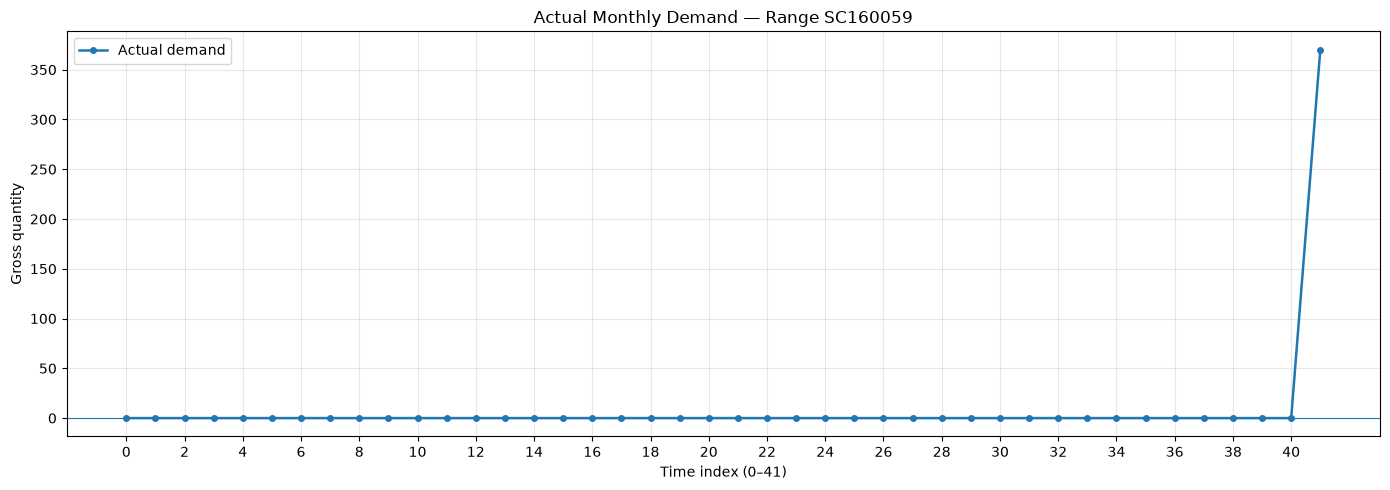

Selected Range: SC160059
Negative months: 0
Zero months: 41
Positive months: 1
 time_idx  gross_qty
        0        0.0
        1        0.0
        2        0.0
        3        0.0
        4        0.0
        5        0.0
        6        0.0
        7        0.0
        8        0.0
        9        0.0
       10        0.0
       11        0.0
       12        0.0
       13        0.0
       14        0.0
       15        0.0
       16        0.0
       17        0.0
       18        0.0
       19        0.0
       20        0.0
       21        0.0
       22        0.0
       23        0.0
       24        0.0
       25        0.0
       26        0.0
       27        0.0
       28        0.0
       29        0.0
       30        0.0
       31        0.0
       32        0.0
       33        0.0
       34        0.0
       35        0.0
       36        0.0
       37        0.0
       38        0.0
       39        0.0
       40        0.0
       41      370.0


In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Randomly select one Range
rng = np.random.default_rng()
range_id = rng.choice(panel["Range"].dropna().unique())

# Extract its monthly observations
df_range = (
    panel[panel["Range"] == range_id]
    .groupby("time_idx", as_index=False)["gross_qty"]
    .sum()
    .sort_values("time_idx")
)

# Ensure all 42 time points appear
df_range = (
    df_range.set_index("time_idx")
    .reindex(range(42), fill_value=0)
    .rename_axis("time_idx")
    .reset_index()
)

# Plot actual demand
plt.figure(figsize=(14, 5))
plt.plot(
    df_range["time_idx"],
    df_range["gross_qty"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="Actual demand",
)

plt.axhline(0, linewidth=0.8)
plt.title(f"Actual Monthly Demand — Range {range_id}")
plt.xlabel("Time index (0–41)")
plt.ylabel("Gross quantity")
plt.xticks(range(0, 42, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Selected Range:", range_id)
print("Negative months:", (df_range["gross_qty"] < 0).sum())
print("Zero months:", (df_range["gross_qty"] == 0).sum())
print("Positive months:", (df_range["gross_qty"] > 0).sum())
print(df_range.to_string(index=False))

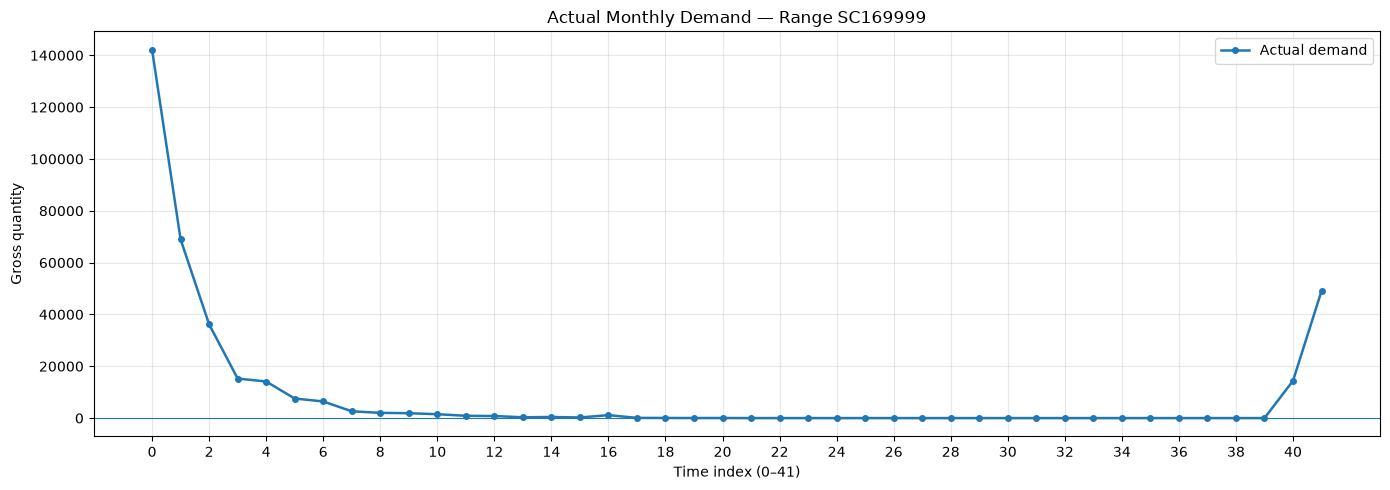

Selected Range: SC169999
Negative months: 0
Zero months: 19
Positive months: 23
 time_idx  gross_qty
        0   142147.0
        1    68934.0
        2    36165.0
        3    15256.0
        4    14115.0
        5     7544.0
        6     6417.0
        7     2620.0
        8     2017.0
        9     1881.0
       10     1495.0
       11      878.0
       12      788.0
       13      299.0
       14      425.0
       15      230.0
       16     1134.0
       17       81.0
       18       47.0
       19       22.0
       20       32.0
       21        0.0
       22        0.0
       23        0.0
       24        0.0
       25        0.0
       26        0.0
       27        0.0
       28        0.0
       29        0.0
       30        0.0
       31        0.0
       32        0.0
       33        0.0
       34        0.0
       35        0.0
       36        0.0
       37        0.0
       38        0.0
       39        0.0
       40    14388.0
       41    49060.0


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Randomly select one Range
rng = np.random.default_rng()
range_id = rng.choice(panel["Range"].dropna().unique())

# Extract its monthly observations
df_range = (
    panel[panel["Range"] == range_id]
    .groupby("time_idx", as_index=False)["gross_qty"]
    .sum()
    .sort_values("time_idx")
)

# Ensure all 42 time points appear
df_range = (
    df_range.set_index("time_idx")
    .reindex(range(42), fill_value=0)
    .rename_axis("time_idx")
    .reset_index()
)

# Plot actual demand
plt.figure(figsize=(14, 5))
plt.plot(
    df_range["time_idx"],
    df_range["gross_qty"],
    marker="o",
    linewidth=1.8,
    markersize=4,
    label="Actual demand",
)

plt.axhline(0, linewidth=0.8)
plt.title(f"Actual Monthly Demand — Range {range_id}")
plt.xlabel("Time index (0–41)")
plt.ylabel("Gross quantity")
plt.xticks(range(0, 42, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Selected Range:", range_id)
print("Negative months:", (df_range["gross_qty"] < 0).sum())
print("Zero months:", (df_range["gross_qty"] == 0).sum())
print("Positive months:", (df_range["gross_qty"] > 0).sum())
print(df_range.to_string(index=False))

In [63]:
raw[["Customer", "Site", "Part", "Range", "Brand", "year", "month", "Qty"]].to_pickle("data/processed/raw_slim.pkl")

NameError: name 'raw' is not defined

In [59]:
_pos = raw[raw["Qty"] > 0]
_cut = _pos["Qty"].quantile(0.99)
_big = _pos[_pos["Qty"] >= _cut]
print(f"99th percentile of one customer-part line: {_cut:,.0f} pairs | lines above it: {len(_big):,} of {len(_pos):,} | share of all units: {_big['Qty'].sum() / _pos['Qty'].sum():.1%}")
_share = (_big.groupby(["year", "month"])["Qty"].sum() / _pos.groupby(["year", "month"])["Qty"].sum()).rename("share of units from top-1% lines")
print(_share.tail(8).round(3).to_string())

# the lines behind SC160023's spike in July and August 2025
_r = raw[(raw["Range"].astype(str) == "SC160023") & (raw["year"] == 2025) & (raw["month"].isin([7, 8]))]
_r.sort_values("Qty", ascending=False).head(10)[["Customer", "Site", "Part", "year", "month", "Qty"]]

NameError: name 'raw' is not defined

In [64]:
dft=pd.read_pickle(project_root / "data" / "processed" / "monthly_demand.pkl")

In [65]:
dft.head()

,time_idx,year,month,gross_qty,return_qty,is_filled,Site,Brand,Range,month_sin,month_cos,range_age_months,lag_1_gross_qty,rolling_mean_3,rolling_mean_6,lag_12_gross_qty,return_rate,return_rate_prev_month,display_id
0,0,2022,4,3440.0,0.0,False,53014,50007.0,SC160040,8.660254e-01,-0.500000,0,NaN,NaN,NaN,NaN,0.0,NaN,53014_50007.0_SC160040_2022-04
1,1,2022,5,2430.0,0.0,False,53014,50007.0,SC160040,5.000000e-01,-0.866025,1,3440.0,NaN,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-05
2,2,2022,6,1293.0,0.0,False,53014,50007.0,SC160040,1.224647e-16,-1.000000,2,2430.0,NaN,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-06
3,3,2022,7,1574.0,0.0,False,53014,50007.0,SC160040,-5.000000e-01,-0.866025,3,1293.0,2387.666667,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-07
4,4,2022,8,3711.0,0.0,False,53014,50007.0,SC160040,-8.660254e-01,-0.500000,4,1574.0,1765.666667,NaN,NaN,0.0,0.0,53014_50007.0_SC160040_2022-08


In [66]:
KEEP = ["Site", "Brand", "Range", "time_idx", "gross_qty", "month_sin", "month_cos", "range_age_months", "lag_1_gross_qty"]
_missing = [c for c in KEEP if c not in dft.columns]
assert not _missing, f"columns not found in monthly_demand: {_missing}"

panel = dft[KEEP].dropna(subset=["gross_qty"]).reset_index(drop=True)          # months with no demand figure yet are not data
panel[["Site", "Brand", "Range"]] = panel[["Site", "Brand", "Range"]].astype(str)

_span = panel.groupby(["Site", "Brand", "Range"])["time_idx"].agg(["min", "max", "count"])
print("rows:", f"{len(panel):,}", "| series:", len(_span), "| months:", int(panel["time_idx"].min()), "to", int(panel["time_idx"].max()),
      "| series with a missing month:", int(((_span["max"] - _span["min"] + 1) != _span["count"]).sum()),
      "| duplicate series-months:", int(panel.duplicated(["Site", "Brand", "Range", "time_idx"]).sum()),
      "| NaN in gross_qty:", int(panel["gross_qty"].isna().sum()))

rows: 20,309 | series: 586 | months: 0 to 41 | series with a missing month: 0 | duplicate series-months: 0 | NaN in gross_qty: 0
